# 10. OSM data for GIS

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Khoshkhah/duckOSM/blob/main/docs/notebooks/10_gis.ipynb) <a href="https://khoshkhah.github.io/duckOSM/notebooks/10_gis.ipynb" download><img src="https://img.shields.io/badge/Download-notebook-F37626?logo=jupyter&logoColor=white" alt="Download the notebook"></a>

<img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/banner-10.svg" alt="duckOSM notebook manual, chapter 10: OSM data for GIS" width="100%">

| **You learn** | the network and the OSM features; the tag rules of OSMnx; features from a network, an area or a file; the network as OSM XML; administrative areas; GeoParquet, GeoPackage and GDAL's layers |
|---|---|
| **Time** | about 2 minutes |
| **Extras** | `duckosm[gis,viz]` (the install cell installs them) |
| **Next** | [11. Mobility data](11_mobility.md): GPS traces, trips and sensors on the network |

In [1]:
# Install duckOSM when it is not installed (for example in Colab). It takes approximately 1 minute.
# Until duckOSM 0.9.0 is on PyPI, the SDK of these notebooks is in the nightly wheel of main (the GitHub pre-release "nightly").
import importlib.util, json, os, urllib.request
def nightly_wheel():       # the address of the newest nightly wheel
    release = json.load(urllib.request.urlopen("https://api.github.com/repos/Khoshkhah/duckOSM/releases/tags/nightly"))
    return next(a["browser_download_url"] for a in release["assets"] if a["name"].endswith(".whl"))
if importlib.util.find_spec("duckosm") is None:      # not installed: install it with the extras of this notebook
    %pip install -q "duckosm[gis,viz] @ {nightly_wheel()}"
import duckosm             # the SDK
if not hasattr(duckosm, "network"):                    # an old duckOSM (0.8.0 or older), without the SDK
    %pip install -q --force-reinstall --no-deps "duckosm @ {nightly_wheel()}"
    raise SystemExit("duckOSM is updated: restart the session (in Colab: Runtime > Restart session), then run this cell again")
print("duckosm", duckosm.__version__)    # the version
# The network of chapter 1 (monaco.duckdb). The chapter opens it. When you run this chapter alone (in Colab), the file
# is not there, so this cell makes it one time.
if not os.path.exists("monaco.duckdb") or not duckosm.open("monaco.duckdb").has_mode("driving", "walking", "cycling"):
    duckosm.network(osm_id=2220322, modes=["driving", "walking", "cycling"], path="monaco.duckdb")

duckosm 0.8.0


## The network and the OSM features

An OSM file holds more than roads. It holds buildings, shops, parks, water, rail lines, bus stops and administrative
areas. Each of these is an OSM **element** (a node, a way or a relation) with **tags**, for example
`amenity=cafe` or `building=yes`.

The chapters before this one used the **network**: duckOSM cuts the roads into edges and nodes, one table for each
mode. A GIS user needs the other elements too, as layers with a geometry. The module `duckosm.gis` gives them.

| You want | The call | Result | OSMnx, QuackOSM, osmium |
|---|---|---|---|
| OSM features with chosen tags | `features` | a GeoDataFrame | OSMnx `features_from_place` |
| the network as an `.osm` file | `to_osm_xml` | an OSM XML file | OSMnx `save_graph_xml` |
| the administrative areas | `admin_boundaries` | a GeoDataFrame | OSMnx `geocode_to_gdf` |
| the table of administrative areas in the file | `admin` | the table `admin_boundaries` | |
| the network as GIS files | `to_gis` | GeoPackage, GeoParquet or shapefiles | OSMnx `save_graph_geopackage` |
| all OSM features as one table | `quack` | GeoParquet, or GDAL's five layers | QuackOSM, `osmium export` |

The work is in Rust (`duckosm quack`, `duckosm admin`) and in DuckDB SQL. Python only makes the GeoDataFrame.
[duckOSM for GIS users](../compare/for-gis-users.md) compares each call with OSMnx, QuackOSM and osmium.

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-key.svg" width="18" height="18" alt=""> **Key idea**
>
> The features come from the same OSM file as the network: the cut file beside the network file. So the buildings, the shops and the roads of your area agree, and an OSM fix that you give to both (chapter [5. Fix the OSM data once](05_osm_fixes.md)) is in both.

## Open the network of chapter 1

Chapter 1 builds Monaco with three modes (driving, walking and cycling) and saves it as `monaco.duckdb`. This chapter opens that file with `duckosm.open`: it builds nothing. `net.save` in chapter 1 put the cut OSM file `monaco.osm.pbf` beside the network file. `features` and
`admin_boundaries` read it.

In [2]:
net = duckosm.open("monaco.duckdb")    # the network of chapter 1: Monaco, three modes
net                                                                         # the card

Network('monaco.duckdb', 52.4 MB, driving 2840 edges, walking 11938 edges, cycling 11305 edges)

## OSM features: `features`

`features(source, tags=...)` gives the OSM features of an area as a GeoDataFrame in EPSG:4326, as OSMnx's
`features_from_*` gives them. The source can be a network (its OSM file beside it), an `Area` of `duckosm.get`, or an
OSM file.

### The tag rules

`tags` is a dict with the rules of OSMnx. The keys are joined with OR: a feature comes when one rule is true.

| Rule | Means | Example |
|---|---|---|
| `{key: True}` | the tag with any value | `{"building": True}` |
| `{key: "value"}` | the tag with this value | `{"amenity": "cafe"}` |
| `{key: [...]}` | the tag with one of the values | `{"amenity": ["cafe", "bar"]}` |
| `None` | all features | |

The result has these columns:

| Column | What it is |
|---|---|
| `feature_id` | the OSM type and id, for example `way/123` |
| one column for each key of `tags` | the value of that tag |
| `tags` | all tags of the feature, as a dict |
| `geometry` | a point, a line or a polygon |

### All buildings

The first call takes each feature with the tag `building`.

In [3]:
buildings = duckosm.gis.features(net, tags={"building": True})    # each feature with the tag building
len(buildings), buildings.geom_type.value_counts().to_dict()       # the number of buildings, by geometry type

(1258, {'Polygon': 1258})

Monaco has 1,258 buildings in OSM, and all are polygons. In OSM a building is a closed way or a multipolygon relation, so `features` gives it as an area, not as a point.

### Three values of one tag

A list takes each of its values. Here: the cafes, the restaurants and the bars.

In [4]:
food = duckosm.gis.features(net, tags={"amenity": ["cafe", "restaurant", "bar"]})    # three values of one tag
food.amenity.value_counts()                                                          # the features of each value

amenity
restaurant    124
cafe           27
bar            21
Name: count, dtype: int64

The city has 124 restaurants, 27 cafes and 21 bars: 172 features. The column `amenity` has the value of the tag for each feature. The map puts them on the gray buildings: most are in La Condamine around the port, in Monte-Carlo and in Fontvieille.

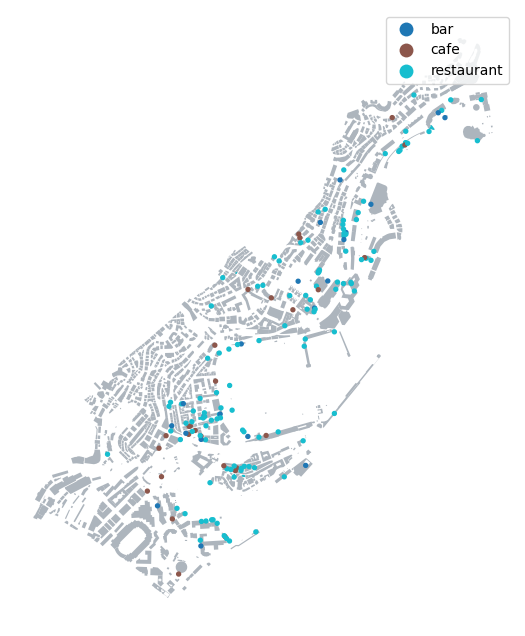

In [5]:
ax = buildings.plot(color="#adb5bd", figsize=(8, 8))                  # the buildings in gray
food.plot(ax=ax, column="amenity", legend=True, markersize=8)         # the cafes, restaurants and bars on them
ax.set_axis_off()                                                     # no axes

### The columns

`food` has the column `amenity`, because `amenity` is the key of `tags`. The column `tags` holds all the tags of each
feature, so you can read a tag that you did not ask for.

In [6]:
food[["feature_id", "amenity", "geometry"]].head()    # the first rows: feature_id, the tag column and the geometry

,feature_id,amenity,geometry
0,node/10005045289,cafe,POINT (7.42245 43.73105)
1,node/10025656390,restaurant,POINT (7.42693 43.73688)
2,node/10025843517,restaurant,POINT (7.42194 43.73674)
3,node/10025852089,bar,POINT (7.42275 43.73699)
4,node/10025852090,restaurant,POINT (7.42251 43.73696)


In [7]:
named = food[food.tags.map(lambda t: "cuisine" in t)]                        # the features with the tag cuisine
named.tags.map(lambda t: t["cuisine"]).value_counts().head()                  # the most common kinds of food

tags
italian        18
pizza           5
coffee_shop     3
burger          3
japanese        3
Name: count, dtype: int64

Each `feature_id` starts with the OSM type: these five places are OSM nodes, so their geometry is a point. The tag `cuisine` is in the column `tags`, not in its own column. The most common kind of food is Italian (18), then pizza (5).

### Two keys: OR

Two keys give each feature that has one of them. Here: the parks and the gardens (`leisure`) or the woods and the
grass (`landuse`), as polygons.

In [8]:
green = duckosm.gis.features(net, tags={"leisure": ["park", "garden"], "landuse": ["grass", "forest"]})    # OR of two keys
green = green[green.geom_type.isin(["Polygon", "MultiPolygon"])]                                       # the areas only
print(len(green), "green areas,", round(green.to_crs(green.estimate_utm_crs()).area.sum() / 1e4, 1), "ha")
green.groupby(["leisure", "landuse"], dropna=False).size()                                              # the features of each value

148 green areas, 21.8 ha


leisure  landuse
garden   NaN        36
park     NaN        14
NaN      forest      4
         grass      94
dtype: int64

The two keys give 148 green polygons with 21.8 ha. 36 are gardens and 14 are parks (`leisure`), 94 are grass and 4 are woods (`landuse`). A feature that has only one of the two keys has `NaN` in the other column.

### From an OSM file

The source can also be an OSM file or an `Area`. Here it is the cut file beside the network file. `tags=None` gives
all features of the file.

In [9]:
pbf = net.path.with_name("monaco.osm.pbf")              # the cut OSM file beside the network
every = duckosm.gis.features(pbf)                        # all features, no tag rule
print(len(every), "features")
every.feature_id.str.split("/").str[0].value_counts()    # the features of each OSM type

9659 features


feature_id
way         5606
node        3994
relation      59
Name: count, dtype: int64

Without `tags`, the call gives all 9,659 features of the file that have tags: 5,606 ways, 3,994 nodes and 59 relations. A node without tags (a point of a road or a building) is not a feature: it is a part of the geometry of a way.

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-tip.svg" width="18" height="18" alt=""> **Tip**
>
> `features(..., fixes="osm_fixes.yaml")` applies an OSM fixes file before it reads the features. Use the same fixes file as the build, and the features and the network agree.

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-warning.svg" width="18" height="18" alt=""> **Warning**
>
> A network that you opened from a file without its OSM file beside it has no source for the features. The call then stops with the error `no OSM file monaco.osm.pbf beside it`. Give the OSM file or the `Area`.

## The network as OSM XML: `to_osm_xml`

`to_osm_xml(view, path)` writes the network of one mode as an OSM XML file (`.osm`), as OSMnx's `save_graph_xml`
writes it. Many tools read OSM XML: JOSM, osmium, SUMO's netconvert, and routing engines.

| Part of the file | What it holds |
|---|---|
| a `<node>` | each node of the roads: the source, the OSM nodes of the road, the target |
| a `<way>` | each road, with the `edge_id` of its forward edge as its id (a two-way road is one way) |
| the tags of a way | `highway`, `name`, `oneway`, `lanes`, `maxspeed`, `layer`, `bridge`, `tunnel` ... |
| `duckosm:osm_id`, `duckosm:edge_id` | the OSM way of the road, and its edge |

The call gives a dict: the path, and the number of nodes and ways. DuckDB writes the file.

In [10]:
import xml.etree.ElementTree as ET                                     # to read the file back

osm = duckosm.gis.to_osm_xml(net.driving, "out/monaco.osm")             # the OSM XML file
root = ET.parse(osm["path"]).getroot()                                 # read it back
osm, len(root.findall("node")), len(root.findall("way"))               # the numbers, and the nodes and ways in the file

({'path': PosixPath('out/monaco.osm'), 'nodes': 5933, 'ways': 1997},
 5933,
 1997)

In [11]:
{t.get("k"): t.get("v") for t in root.find("way").iter("tag")}         # the tags of the first way

{'highway': 'service',
 'oneway': 'no',
 'lanes': '2',
 'lanes:forward': '1',
 'lanes:backward': '1',
 'maxspeed': '20',
 'duckosm:osm_id': '177052163',
 'duckosm:edge_id': '2214154189574909'}

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-output.svg" width="18" height="18" alt=""> **What the output shows**
>
> The file has 5,933 nodes and 1,997 ways. The network has 2,840 driving edges, but a two-way road is one way in OSM XML, so the file has fewer ways than edges. The first way is a two-way service road with two lanes, one in each direction (`lanes:forward`, `lanes:backward`), and a speed limit of 20 km/h. `duckosm:osm_id` is the OSM way of the road, and `duckosm:edge_id` is its forward edge: your data joins to it.

## Administrative areas

### The areas as a GeoDataFrame: `admin_boundaries`

`admin_boundaries(net)` gives the administrative areas of the network's area: one row for each OSM boundary relation,
with `osm_id`, `name`, `admin_level`, the parent area and the geometry. The `admin_level` tells the kind of area: 2 is a
country, and larger numbers are smaller areas. In Monaco, 8 is the city and 10 is a quarter.

When the database has no table `admin_boundaries`, the call adds it first from the OSM file beside the network. The
next call reads the table.

In [12]:
admin = duckosm.gis.admin_boundaries(net)                     # the administrative areas
admin.drop(columns="geometry")                                # the table, without the geometry

,osm_id,name,name_en,admin_level,parent_osm_id
0,2220322,Monaco,Monaco,8,<NA>
1,2220206,Fontvieille,None,10,2220322
2,5986473,Jardin Exotique,None,10,2220322
3,2221178,La Condamine,None,10,2220322
4,5986436,La Rousse,None,10,2220322
5,5986437,Larvotto,None,10,2220322
6,5986474,Les Monegetti,None,10,2220322
7,2220207,Monaco-Ville,None,10,2220322
8,5986438,Monte-Carlo,None,10,2220322
9,5986475,Ravin de Sainte-Dévote,None,10,2220322


> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-output.svg" width="18" height="18" alt=""> **What the output shows**
>
> The area has 10 administrative areas: the city of Monaco (`admin_level` 8) and its nine quarters (10). The column `parent_osm_id` of each quarter is 2220322, the city. The map shows the quarters, each in its own color, with the roads on them. Some roads are outside all quarters: they cross the boundary of the city, and the build keeps them whole.

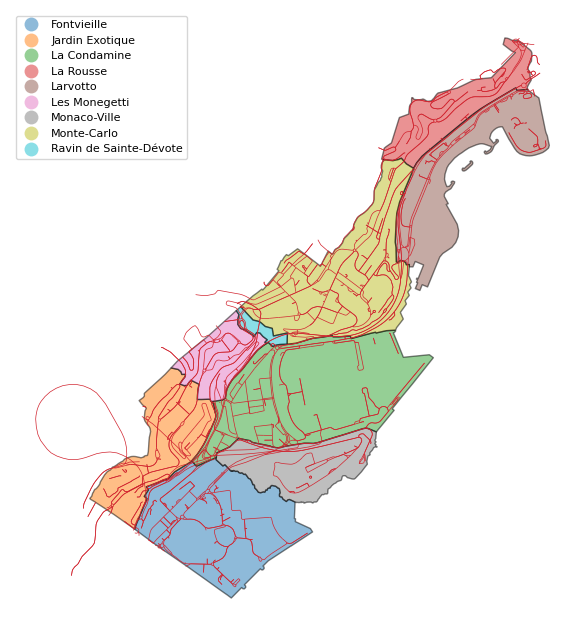

In [13]:
quarters = admin[admin.admin_level == 10]                     # level 10: the quarters
ax = quarters.plot(column="name", alpha=0.5, edgecolor="black", legend=True, figsize=(8, 8),
                   legend_kwds={"loc": "upper left", "fontsize": 8})    # each quarter in its own color
net.driving.edges().plot(ax=ax, color="#d1242f", linewidth=0.5)       # the roads on them
ax.set_axis_off()                                             # no axes

### Which quarter is each road in

The quarters are polygons, so a spatial join gives the quarter of each edge. Here the join uses one point on
each edge.

In [14]:
import geopandas as gpd

edges = net.driving.edges()                                                               # the driving edges
mid = edges.set_geometry(edges.geometry.representative_point())                  # a point on each edge
q = quarters[["name", "geometry"]].rename(columns={"name": "quarter"})            # the quarters, with the column quarter
inq = gpd.sjoin(mid, q, predicate="within")                                       # the quarter of each middle point
inq.groupby("quarter").length_m.sum().div(1000).round(1).sort_values(ascending=False)   # km of driving edges in each quarter

quarter
Monte-Carlo               20.0
La Condamine              15.6
Fontvieille               11.2
Jardin Exotique           10.5
Larvotto                   9.3
La Rousse                  7.3
Monaco-Ville               6.7
Les Monegetti              6.5
Ravin de Sainte-Dévote     1.1
Name: length_m, dtype: float64

Monte-Carlo has the most driving roads: 20.0 km of edges. La Condamine has 15.6 km and Fontvieille 11.2 km. Ravin de Sainte-Dévote, the smallest quarter, has 1.1 km. An edge outside all quarters has no row.

### The table in the file: `admin`

`admin(net, pbf)` is the call that `admin_boundaries` uses. It runs `duckosm admin`: it reads the boundary relations
of the OSM file `pbf` (or an `Area`) and writes the table `admin_boundaries` into the database, in place. `gpkg=` also
writes a GeoPackage. Use it when you want the table in the file for your own SQL, without a GeoDataFrame.

In [15]:
duckosm.gis.admin(net, pbf)                                               # the table admin_boundaries, written again
net.sql("SELECT admin_level, count(*) AS areas FROM main.admin_boundaries GROUP BY 1 ORDER BY 1")    # the areas of each level

,admin_level,areas
0,8,1
1,10,9


## GIS files

### The network as GIS files: `to_gis`

`to_gis(net, out, fmt=...)` writes the edges and the nodes of the modes as GIS files. `net.to_gis(...)` is the same
call. Chapter [6. Exports](06_exports.md) writes a GeoPackage. Here the format is GeoParquet, one file for each layer.

| Argument | Default | What it does |
|---|---|---|
| `out` | | the file (GeoPackage) or the folder (GeoParquet, shapefiles) |
| `fmt` | `"gpkg"` | `"gpkg"`, `"geoparquet"` or `"shp"` |
| `modes` / `mode` | all modes | the modes to write (a mode view writes its mode) |
| `boundary` | `True` | also the boundary of the area |
| `srs` | `"EPSG:4326"` | the coordinate system of the files |

In [16]:
files = duckosm.gis.to_gis(net.driving, "out/gis", fmt="geoparquet")       # one GeoParquet file for each layer
files["layers"]                                                              # the layers that it wrote

{'edges_driving': 2840,
 'nodes_driving': 1768,
 'boundary': 1,
 'features_buildings': 1259,
 'features_land': 246,
 'features_ocean': 1,
 'features_paved': 83,
 'features_place_labels': 10,
 'features_pois': 1653,
 'features_public_transport': 107,
 'features_sites': 86,
 'features_streets': 3513,
 'features_traffic': 574,
 'features_water_lines': 4,
 'features_water_polygons': 91}

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-output.svg" width="18" height="18" alt=""> **What the output shows**
>
> `files["layers"]` gives each layer and its rows: the driving edges (2,840), the nodes (1,768) and the boundary. A mode view writes only its mode, but the file also has the base map, so the call writes its layers too (`features_buildings`, `features_pois`, `features_streets` and more).

### All OSM features as layers: `quack`

`quack(source, ...)` runs `duckosm quack` on an OSM file or an `Area`. It writes all the features of the file as one
table, as QuackOSM does (`formats=["geoparquet"]`), or, with `gdal=True`, as the five layers of GDAL's OSM driver in
one GeoPackage: points, lines, multilinestrings, multipolygons and other relations. `features` uses this table. Chapter
[6. Exports](06_exports.md) shows the QuackOSM table. This chapter shows GDAL's layers.

In [17]:
layers = duckosm.gis.quack(pbf, out="out", name="monaco", gdal=True)    # GDAL's five layers
import geopandas as gpd
gpkg = layers[0]                                                        # the GeoPackage
{name: len(gpd.read_file(gpkg, layer=name)) for name in gpd.list_layers(gpkg).name}    # the features of each layer

out/monaco_gdal.gpkg

{'points': 3997,
 'lines': 3856,
 'multilinestrings': 69,
 'multipolygons': 1809,
 'other_relations': 129}

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-output.svg" width="18" height="18" alt=""> **What the output shows**
>
> The call wrote one GeoPackage, `monaco_gdal.gpkg`, with GDAL's five layers: 3,997 points, 3,856 lines, 69 multilinestrings, 1,809 multipolygons and 129 other relations. These are the layers that GDAL's own OSM driver (`ogr2ogr`) gives for the same file, so a tool that reads them from GDAL can read this file.

## Try it yourself

**1.** Get the bus stops of Monaco (`highway=bus_stop`) and count them.

<details><summary>Show the answer</summary>

```python
stops = duckosm.gis.features(net, tags={"highway": "bus_stop"})
len(stops)
```
</details>

**2.** Get all features with the tag `shop`, and give the five most common kinds of shop.

<details><summary>Show the answer</summary>

```python
shops = duckosm.gis.features(net, tags={"shop": True})
shops["shop"].value_counts().head()
```
</details>

**3.** Write the walking network as OSM XML, and count its ways.

<details><summary>Show the answer</summary>

```python
walk = duckosm.open("monaco.duckdb")
duckosm.gis.to_osm_xml(walk.walking, "out/monaco_walk.osm")["ways"]
```
</details>

**4.** Count the restaurants in each quarter of Monaco.

<details><summary>Show the answer</summary>

```python
r = food[food.amenity == "restaurant"]
r = r.set_geometry(r.geometry.representative_point())
gpd.sjoin(r, quarters[["name", "geometry"]], predicate="within").name.value_counts()
```
</details>

## Words in this chapter

| Word | Meaning |
|---|---|
| element | one object of OSM data: a node, a way or a relation |
| tag | a key and a value of an element, for example `amenity=cafe` |
| feature | an OSM element with its tags and its geometry: a row of `features` |
| `feature_id` | the OSM type and id of a feature, for example `way/123` |
| OSM XML | the text format of OSM data (`.osm`) |
| administrative area | an area of government: a country, a region, a city, a quarter |
| `admin_level` | the kind of an administrative area: 2 is a country, larger numbers are smaller areas |
| GeoParquet | a Parquet file with a geometry column |
| GeoPackage | one SQLite file with GIS layers (`.gpkg`) |

## Summary

| Call | Does |
|---|---|
| `duckosm.gis.features(source, tags=...)` | OSM features as a GeoDataFrame |
| `duckosm.gis.to_osm_xml(view, path)` | the network of one mode as an OSM XML file |
| `duckosm.gis.admin_boundaries(net)` | the administrative areas as a GeoDataFrame |
| `duckosm.gis.admin(net, pbf, gpkg=...)` | the table `admin_boundaries` in the database |
| `duckosm.gis.to_gis(net, out, fmt=...)` | the network as GeoPackage, GeoParquet or shapefiles |
| `duckosm.gis.quack(source, gdal=...)` | all OSM features as one table, or GDAL's five layers |

The reference: [duckosm.gis](../reference/sdk/gis.md). **Next:** [11. Mobility data](11_mobility.md), GPS traces, trips and sensors on the network.